In [2]:
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
adj_matrix = [
    [0,1,1,0],
    [1,0,1,1],
    [1,1,0,1],
    [0,1,1,0]
]
G = nx.from_numpy_array(np.array(adj_matrix))


In [3]:
print("Bac cua cac dinh: ", dict(G.degree()))

Bac cua cac dinh:  {0: 2, 1: 3, 2: 3, 3: 2}


In [4]:
dfs_nodes = list(nx.dfs_preorder_nodes(G, source=0))
bfs_nodes = list(nx.bfs_tree(G, source=0).nodes())
print("DFS tu dinh 0 ", dfs_nodes)
print("BFS tu dinh 0", bfs_nodes)

DFS tu dinh 0  [0, 1, 2, 3]
BFS tu dinh 0 [0, 1, 2, 3]


In [5]:
print("So thanh phan lien thong: ", nx.number_connected_components(G))

So thanh phan lien thong:  1


In [6]:
for u, v in G.edges():
    G[u][v]['weight']=1
shortest_path = nx.dijkstra_path(G, source= 0, target= 3, weight= 'weight')
print(shortest_path)

[0, 1, 3]


In [7]:
mst = nx.minimum_spanning_tree(G, weight='weight')
print(list(mst.edges()))

[(0, 1), (0, 2), (1, 3)]


In [9]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.datasets import load_wine



In [11]:
data = load_wine()
X, y = data.data, data.target
X_train, X_test, y_train , y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [13]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [14]:
pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

In [15]:
print("Tỷ lệ phương sai giải thích bởi 2 thành phần chính:", pca.explained_variance_ratio_)

Tỷ lệ phương sai giải thích bởi 2 thành phần chính: [0.36196226 0.18763862]


In [16]:
clf = LogisticRegression(random_state=42)
clf.fit(X_train_pca, y_train)
y_pred = clf.predict(X_test_pca)
print("Accuracy: ", accuracy_score(y_test, y_pred))

Accuracy:  0.9629629629629629


In [20]:
from scipy.linalg import svd
A = np.array([
    [3, 2, 2],
    [2, 3, -2]
])
U, S, Vt = svd(A)
print("ma tran U: ", U)
print("Cac gia tri ki di S : ", S)
print("ma tran Vt: ", Vt)

ma tran U:  [[-0.70710678 -0.70710678]
 [-0.70710678  0.70710678]]
Cac gia tri ki di S :  [5. 3.]
ma tran Vt:  [[-7.07106781e-01 -7.07106781e-01 -6.47932334e-17]
 [-2.35702260e-01  2.35702260e-01 -9.42809042e-01]
 [-6.66666667e-01  6.66666667e-01  3.33333333e-01]]


In [21]:
pinv_A = np.linalg.pinv(A)
print(pinv_A)

[[ 0.15555556  0.04444444]
 [ 0.04444444  0.15555556]
 [ 0.22222222 -0.22222222]]


In [22]:
ratings_data = np.array([
    [5, 3, np.nan, 1],
    [4, np.nan, 4, 5],
    [np.nan, 3, 5, 4],
    [2, 2, np.nan, np.nan]
])

In [23]:
R = np.nan_to_num(ratings_data, nan = 0.0)
num_users , num_items = R.shape
K = 2 
lr = 0.01
epochs = 500
lam = 0.1
np.random.seed(42)
P = np.random.normal(0, 0.1, (num_users, K))
Q = np.random.normal(0, 0.1, (num_items, K))

In [24]:
for epoch in range(epochs):
    for i in range(num_users):
        for j in range(num_items):
            if R[i,j]>0:
                pred = np.dot(P[i,:], Q[j,:])
                err = R[i,j]- pred
                P[i, :] += lr*(err*Q[j,:] - lam*P[i,:])
                Q[j, :] += lr*(err*P[i,:] - lam*Q[j,:])

In [26]:
R_pred = np.dot(P, Q.T)
print("ma tran du doan")
print(np.round(R_pred, 2))



ma tran du doan
[[ 4.73  2.86 -0.38  1.18]
 [ 3.94  4.08  4.18  4.52]
 [ 1.75  2.86  4.62  4.18]
 [ 2.    1.89  1.64  1.91]]


In [27]:
mask = R> 0
rmse = np.sqrt(np.mean((R[mask]- R_pred[mask])**2))
print(rmse)

0.23347957956759152


In [28]:
import numpy as np
import pandas as pd
from sklearn.linear_model import Ridge
from sklearn.feature_extraction.text import TfidfVectorizer

# Giả lập ma trận ratings (User x Item), NaN là chưa đánh giá
ratings = np.array([
    [5, 5, 0, np.nan],
    [5, np.nan, 1, 4],
    [1, 4, np.nan, np.nan]
])

# Giả lập feature vectors của item (X) hoặc tạo từ TF-IDF tên môn học/item
item_features = np.array([
    [0.99, 0.02],
    [0.91, 0.11],
    [0.01, 0.99],
    [0.03, 0.98]
])

# Huấn luyện mô hình tìm theta (W) cho từng user dựa trên các item đã chấm điểm
thetas = []
for i in range(len(ratings)):
    user_ratings = ratings[i]
    rated_idx = np.where(~np.isnan(user_ratings))[0]
    
    if len(rated_idx) > 0:
        X_train = item_features[rated_idx]
        y_train = user_ratings[rated_idx]
        
        # Dùng Ridge hoặc lstsq
        ridge = Ridge(alpha=1.0)
        ridge.fit(X_train, y_train)
        thetas.append(ridge.coef_)
    else:
        thetas.append(np.zeros(item_features.shape[1]))

thetas = np.array(thetas)

# Dự đoán điểm các ô còn thiếu (?)
predicted_ratings = np.dot(item_features, thetas.T).T
print("Ma trận điểm dự đoán (Content-based):\n", np.round(predicted_ratings, 2))

Ma trận điểm dự đoán (Content-based):
 [[ 1.4   1.16 -1.39 -1.35]
 [ 0.71  0.59 -0.7  -0.68]
 [-0.12 -0.09  0.13  0.13]]


In [29]:
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity

# Thay thế NaN bằng 0 để tính toán độ tương đồng
filled_ratings = np.nan_to_num(ratings, nan=0.0)

# Tính độ tương đồng giữa các Item (để tính Item-Item, chuyển vị .T)
item_similarity = cosine_similarity(filled_ratings.T)
print("Ma trận độ tương đồng Item-Item:\n", np.round(item_similarity, 2))

# Hoặc tính độ tương đồng giữa các User (User-User)
user_similarity = cosine_similarity(filled_ratings)
print("Ma trận độ tương đồng User-User:\n", np.round(user_similarity, 2))

Ma trận độ tương đồng Item-Item:
 [[1.   0.63 0.7  0.7 ]
 [0.63 1.   0.   0.  ]
 [0.7  0.   1.   1.  ]
 [0.7  0.   1.   1.  ]]
Ma trận độ tương đồng User-User:
 [[1.   0.55 0.86]
 [0.55 1.   0.19]
 [0.86 0.19 1.  ]]


In [30]:
import numpy as np

# R là ma trận User-Item (M x N), gán 0 cho ô trống
R = np.nan_to_num(ratings, nan=0.0)
num_users, num_items = R.shape
K = 2          # Số chiều ẩn (latent factors)
lr = 0.01      # Learning rate
epochs = 200
lam = 0.1      # Regularization

# Khởi tạo ma trận P (User) và Q (Item)
np.random.seed(42)
P = np.random.normal(0, 0.1, (num_users, K))
Q = np.random.normal(0, 0.1, (num_items, K))

# Vòng lặp tối ưu Gradient Descent
for epoch in range(epochs):
    for i in range(num_users):
        for j in range(num_items):
            if R[i, j] > 0: # Chỉ học trên dữ liệu thực tế
                pred = np.dot(P[i, :], Q[j, :])
                err = R[i, j] - pred
                
                # Cập nhật P và Q
                P[i, :] += lr * (err * Q[j, :] - lam * P[i, :])
                Q[j, :] += lr * (err * P[i, :] - lam * Q[j, :])

# Dự đoán toàn bộ ma trận
R_pred = np.dot(P, Q.T)
print("Ma trận dự đoán bằng Matrix Factorization:\n", np.round(R_pred, 2))

Ma trận dự đoán bằng Matrix Factorization:
 [[4.76 4.99 0.97 3.89]
 [4.81 4.83 0.97 3.89]
 [1.29 3.67 0.4  1.48]]


--- 1. THỰC HIỆN SVD CHO MA TRẬN A ---
Ma trận U:
 [[-0.70710678 -0.70710678]
 [-0.70710678  0.70710678]]
Giá trị kỳ dị S:
 [5. 3.]
Ma trận Vt:
 [[-7.07106781e-01 -7.07106781e-01 -6.47932334e-17]
 [-2.35702260e-01  2.35702260e-01 -9.42809042e-01]
 [-6.66666667e-01  6.66666667e-01  3.33333333e-01]]

Pseudo inverse của A:
 [[ 0.15555556  0.04444444]
 [ 0.04444444  0.15555556]
 [ 0.22222222 -0.22222222]]

--- 2. NÉN ẢNH BẰNG SVD ---
Không có kết nối mạng để tải data.chelsea(), đang tạo ảnh ma trận ngẫu nhiên để thay thế...


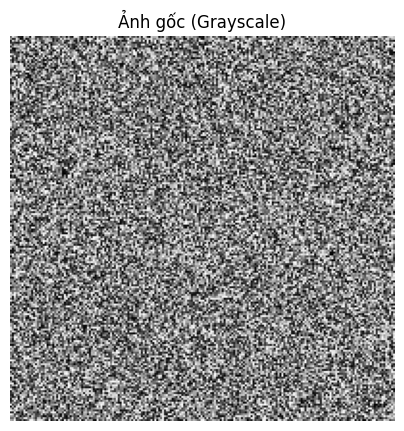

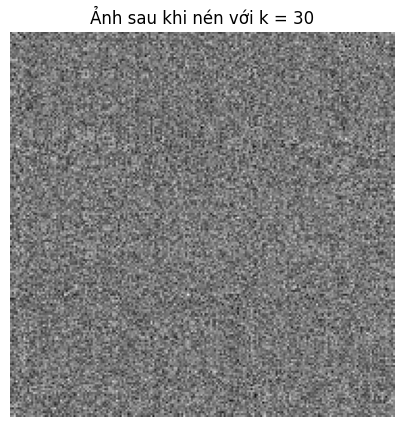

In [32]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import svd

# Cho phép hiển thị hình ảnh trực tiếp trong Jupyter Notebook
%matplotlib inline

print("--- 1. THỰC HIỆN SVD CHO MA TRẬN A ---")
A = np.array([
    [3, 2, 2],
    [2, 3, -2]
])

U, S, Vt = svd(A)
print("Ma trận U:\n", U)
print("Giá trị kỳ dị S:\n", S)
print("Ma trận Vt:\n", Vt)

# Tính Pseudo inverse
pinv_A = np.linalg.pinv(A)
print("\nPseudo inverse của A:\n", pinv_A)


print("\n--- 2. NÉN ẢNH BẰNG SVD ---")
print("Không có kết nối mạng để tải data.chelsea(), đang tạo ảnh ma trận ngẫu nhiên để thay thế...")
    # Tạo một ảnh xám giả lập (ma trận 200x200 giá trị từ 0 đến 1) để test thuật toán SVD
np.random.seed(42)
image_gray = np.random.rand(200, 200)

# Hiển thị ảnh gốc / ảnh giả lập
plt.figure(figsize=(5, 5))
plt.imshow(image_gray, cmap='gray')
plt.title("Ảnh gốc (Grayscale)")
plt.axis('off')
plt.show()

# Áp dụng SVD để nén ảnh (giữ lại k giá trị kỳ dị hàng đầu)
U_img, S_img, Vt_img = svd(image_gray)
k = 30  # Số lượng thành phần giữ lại để nén
image_compressed = np.dot(U_img[:, :k], np.dot(np.diag(S_img[:k]), Vt_img[:k, :]))

# Hiển thị kết quả sau khi nén
plt.figure(figsize=(5, 5))
plt.imshow(image_compressed, cmap='gray')
plt.title(f"Ảnh sau khi nén với k = {k}")
plt.axis('off')
plt.show()